# Object detection transfer learning

### Yolov2 architecture

In [1]:
import torch
import torch.nn as nn

class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size,
                 stride=1, batch_norm=True, activation=True):
        super().__init__()
        padding = (kernel_size - 1) // 2
        self.conv = nn.Conv2d(
            in_channels, out_channels, kernel_size, stride, padding,
            bias=not batch_norm,
        )
        self.bn = nn.BatchNorm2d(out_channels) if batch_norm else nn.Identity()
        self.activation = nn.LeakyReLU(0.1, inplace=True) if activation else nn.Identity()

    def forward(self, x):
        return self.activation(self.bn(self.conv(x)))


class ReorgLayer(nn.Module):
    def __init__(self, stride=2):
        super().__init__()
        self.stride = stride
 
    def forward(self, x):
        B, C, H, W = x.shape
        s = self.stride
        x = x.view(B, C, H // s, s, W // s, s)
        x = x.permute(0, 3, 5, 1, 2, 4).contiguous()
        x = x.view(B, C * s * s, H // s, W // s)
        return x

class DarknetStageA(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            ConvBlock(3, 32, 3), nn.MaxPool2d(2, 2),
            ConvBlock(32, 64, 3), nn.MaxPool2d(2, 2),

            ConvBlock(64, 128, 3),
            ConvBlock(128, 64, 1),
            ConvBlock(64, 128, 3), nn.MaxPool2d(2, 2),

            ConvBlock(128, 256, 3),
            ConvBlock(256, 128, 1),
            ConvBlock(128, 256, 3), nn.MaxPool2d(2, 2),

            ConvBlock(256, 512, 3),
            ConvBlock(512, 256, 1),
            ConvBlock(256, 512, 3),
            ConvBlock(512, 256, 1),
            ConvBlock(256, 512, 3),
        )

    def forward(self, x):
        return self.net(x)


class DarknetStageB(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.MaxPool2d(2, 2),
            ConvBlock(512, 1024, 3),
            ConvBlock(1024, 512, 1),
            ConvBlock(512, 1024, 3),
            ConvBlock(1024, 512, 1),
            ConvBlock(512, 1024, 3),
        )

    def forward(self, x):
        return self.net(x)


class DetectionHead(nn.Module):
    def __init__(self, num_classes=80, num_anchors=5):
        super().__init__()
        self.pre_route = nn.Sequential(
            ConvBlock(1024, 1024, 3),
            ConvBlock(1024, 1024, 3),
        )
        self.passthrough_reduce = ConvBlock(512, 64, 1)
        self.reorg = ReorgLayer(stride=2)

        self.post_route = ConvBlock(1280, 1024, 3)

        out_channels = num_anchors * (5 + num_classes)
        self.final_conv = ConvBlock(
            1024, out_channels, 1, batch_norm=False, activation=False
        )

    def forward(self, backbone_out, passthrough_src):
        x = self.pre_route(backbone_out)

        p = self.passthrough_reduce(passthrough_src)
        p = self.reorg(p)

        x = torch.cat([p, x], dim=1)
        x = self.post_route(x)
        x = self.final_conv(x)
        return x


class YOLOv2(nn.Module):
    def __init__(self, num_classes=80, num_anchors=5):
        super().__init__()
        self.num_classes = num_classes
        self.num_anchors = num_anchors

        self.stage_a = DarknetStageA()
        self.stage_b = DarknetStageB()
        self.head = DetectionHead(num_classes, num_anchors)

        self.anchors = torch.tensor([
            [0.57273, 0.677385],
            [1.87446, 2.06253],
            [3.33843, 5.47434],
            [7.88282, 3.52778],
            [9.77052, 9.16828],
        ])

    def forward(self, x):
        passthrough_src = self.stage_a(x)
        backbone_out = self.stage_b(passthrough_src)
        out = self.head(backbone_out, passthrough_src)
        return out


if __name__ == "__main__":
    model = YOLOv2(num_classes=3, num_anchors=5)
    dummy = torch.randn(1, 3, 608, 608)
    out = model(dummy)

    print(out.shape)
    n_params = sum(p.numel() for p in model.parameters())
    print(f"{n_params:,}")

torch.Size([1, 40, 19, 19])
50,568,264


### We are turning darknet weights into pytorch

In [4]:
import numpy as np
def load_darknet_weights(model, weight_file):
    with open(weight_file, "rb") as f:
        # FIX: YOLOv2 headers are 4 int32s (major, minor, revision, seen)
        _ = np.fromfile(f, dtype=np.int32, count=4)
        weights = np.fromfile(f, dtype=np.float32)
        
    ptr = 0
    for m in model.modules():
        if m.__class__.__name__ == "ConvBlock":
            conv = m.conv
            
            # If batch_norm is active
            if getattr(m, 'bn', None) is not None and not isinstance(m.bn, nn.Identity):
                num_bn = m.bn.bias.numel()
                num_conv = conv.weight.numel()
                
                # FIX: Check if we have enough weights left for this entire block
                if ptr + (num_bn * 4) + num_conv > len(weights):
                    print(f"Backbone weights loaded. Stopping at custom layers ({ptr}/{len(weights)} loaded).")
                    break
                
                # Darknet saves Batch Norm in this specific order
                m.bn.bias.data.copy_(torch.from_numpy(weights[ptr : ptr + num_bn]).view_as(m.bn.bias))
                ptr += num_bn
                
                m.bn.weight.data.copy_(torch.from_numpy(weights[ptr : ptr + num_bn]).view_as(m.bn.weight))
                ptr += num_bn
                
                m.bn.running_mean.data.copy_(torch.from_numpy(weights[ptr : ptr + num_bn]).view_as(m.bn.running_mean))
                ptr += num_bn
                
                m.bn.running_var.data.copy_(torch.from_numpy(weights[ptr : ptr + num_bn]).view_as(m.bn.running_var))
                ptr += num_bn
                
                # Load Conv weights
                conv.weight.data.copy_(torch.from_numpy(weights[ptr : ptr + num_conv]).view_as(conv.weight))
                ptr += num_conv
                
            else:
                # No Batch Norm
                num_conv_bias = conv.bias.numel()
                num_conv = conv.weight.numel()
                
                if ptr + num_conv_bias + num_conv > len(weights):
                    print(f"Backbone weights loaded. Stopping at custom layers ({ptr}/{len(weights)} loaded).")
                    break
                    
                conv.bias.data.copy_(torch.from_numpy(weights[ptr : ptr + num_conv_bias]).view_as(conv.bias))
                ptr += num_conv_bias
                
                conv.weight.data.copy_(torch.from_numpy(weights[ptr : ptr + num_conv]).view_as(conv.weight))
                ptr += num_conv
                
    return model

In [5]:
model = load_darknet_weights(model, "darknet19_448.conv.23")

Backbone weights loaded. Stopping at custom layers (19831776/19831776 loaded).


### Download the dataset and create pytorch dataset, dataloader and transforms

In [ ]:
import os
import glob
import torch
import torch.nn as nn
import torch.optim as optim
import xml.etree.ElementTree as ET
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import numpy as np

# Download BCCD Dataset directly from GitHub
!git clone https://github.com/Shenggan/BCCD_Dataset.git

BCCD_PATH = "./BCCD_Dataset/BCCD"
IMAGE_DIR = os.path.join(BCCD_PATH, "JPEGImages")
ANNOTATION_DIR = os.path.join(BCCD_PATH, "Annotations")

CLASSES = ['RBC', 'WBC', 'Platelets']
NUM_CLASSES = len(CLASSES)
IMG_SIZE = 608 # YOLOv2 standard input size
GRID_SIZE = IMG_SIZE // 32 # 19x19 grid

fatal: destination path 'BCCD_Dataset' already exists and is not an empty directory.


In [ ]:
class BCCDDataset(Dataset):
    def __init__(self, image_dir, annotation_dir, anchors, transform=None):
        self.image_dir = image_dir
        self.annotation_paths = glob.glob(os.path.join(annotation_dir, "*.xml"))
        self.anchors = anchors # Expected shape: [5, 2]
        self.transform = transform
        
    def __len__(self):
        return len(self.annotation_paths)
    
    def __getitem__(self, idx):
        xml_path = self.annotation_paths[idx]
        tree = ET.parse(xml_path)
        root = tree.getroot()
        
        # Load image
        img_filename = root.find("filename").text
        img_path = os.path.join(self.image_dir, img_filename)
        image = Image.open(img_path).convert("RGB")
        orig_w, orig_h = image.size
        
        if self.transform:
            image = self.transform(image)
            
        # Target tensor shape: [num_anchors, grid_size, grid_size, 5 + num_classes]
        # 5 comes from: [objectness, cx, cy, w, h]
        target = torch.zeros((len(self.anchors), GRID_SIZE, GRID_SIZE, 5 + NUM_CLASSES))
        
        for obj in root.findall("object"):
            class_name = obj.find("name").text
            if class_name not in CLASSES:
                continue
            class_id = CLASSES.index(class_name)
            
            bndbox = obj.find("bndbox")
            xmin = float(bndbox.find("xmin").text) / orig_w
            ymin = float(bndbox.find("ymin").text) / orig_h
            xmax = float(bndbox.find("xmax").text) / orig_w
            ymax = float(bndbox.find("ymax").text) / orig_h
            
            # Convert to center x, center y, width, height (normalized 0 to 1)
            cx, cy = (xmin + xmax) / 2.0, (ymin + ymax) / 2.0
            w, h = xmax - xmin, ymax - ymin
            
            # Find grid cell coordinates
            cell_x, cell_y = int(cx * GRID_SIZE), int(cy * GRID_SIZE)
            
            # Find best anchor (simplified: match by shape/aspect ratio)
            # In a full implementation, you compute IoU between the true box and anchor boxes
            anchor_ious = []
            for a_w, a_h in self.anchors:
                # Compare width/height ratios
                inter = min(w, a_w) * min(h, a_h)
                union = (w * h) + (a_w * a_h) - inter
                anchor_ious.append(inter / (union + 1e-6))
            
            best_anchor = np.argmax(anchor_ious)
            
            # Populate target tensor (Only if no object is already assigned to this exact anchor/cell)
            if target[best_anchor, cell_y, cell_x, 0] == 0:
                target[best_anchor, cell_y, cell_x, 0] = 1.0 # Objectness score
                
                # Bbox coordinates relative to the cell
                target[best_anchor, cell_y, cell_x, 1:5] = torch.tensor([
                    cx * GRID_SIZE - cell_x, # cx relative to cell (0 to 1)
                    cy * GRID_SIZE - cell_y, # cy relative to cell (0 to 1)
                    torch.log(torch.tensor(w / self.anchors[best_anchor][0] + 1e-16)), # w transform
                    torch.log(torch.tensor(h / self.anchors[best_anchor][1] + 1e-16))  # h transform
                ])
                
                # One-hot encode class
                target[best_anchor, cell_y, cell_x, 5 + class_id] = 1.0
                
        return image, target

# Transform and DataLoaders
transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
])

# Define anchors (normalized standard YOLO anchors)
anchors = torch.tensor([[0.57, 0.67], [1.87, 2.06], [3.33, 5.47], [7.88, 3.52], [9.77, 9.16]]) / GRID_SIZE

dataset = BCCDDataset(IMAGE_DIR, ANNOTATION_DIR, anchors, transform=transform)

# Split 80/20 train/val
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = torch.utils.data.random_split(dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=4, shuffle=False)

### This cell defines the yolo loss

In [ ]:
class YOLOv2Loss(nn.Module):
    def __init__(self):
        super().__init__()
        self.mse = nn.MSELoss(reduction="sum")
        self.bce = nn.BCEWithLogitsLoss(reduction="sum")
        self.cross_entropy = nn.CrossEntropyLoss(reduction="sum")
        
        self.lambda_coord = 5.0
        self.lambda_noobj = 0.5
        
    def forward(self, predictions, target):
        # predictions shape: [B, 5 * (5 + 3), 19, 19]
        B = predictions.shape[0]
        # Reshape to [B, anchors, grid_y, grid_x, 5 + classes]
        predictions = predictions.view(B, 5, 5 + NUM_CLASSES, GRID_SIZE, GRID_SIZE).permute(0, 1, 3, 4, 2)
        
        # Masks for object / no object
        obj_mask = target[..., 0] == 1 # [B, 5, 19, 19]
        noobj_mask = target[..., 0] == 0
        
        # 1. No Object Loss (Penalize objectness score if nothing is there)
        noobj_loss = self.bce(predictions[..., 0][noobj_mask], target[..., 0][noobj_mask])
        
        # 2. Object Loss (Encourage objectness score if something is there)
        obj_loss = self.bce(predictions[..., 0][obj_mask], target[..., 0][obj_mask])
        
        # 3. Coordinate Loss (Center x,y and width,height)
        coord_loss = self.mse(torch.sigmoid(predictions[..., 1:3][obj_mask]), target[..., 1:3][obj_mask])
        coord_loss += self.mse(predictions[..., 3:5][obj_mask], target[..., 3:5][obj_mask])
        
        # 4. Class Loss
        class_loss = self.cross_entropy(predictions[..., 5:][obj_mask], torch.argmax(target[..., 5:][obj_mask], dim=1))
        
        # Combine weighted losses
        total_loss = (self.lambda_coord * coord_loss) + obj_loss + (self.lambda_noobj * noobj_loss) + class_loss
        return total_loss / B # average over batch

### This cell calculates loss on given set of images

In [ ]:
def evaluate_model(model, dataloader, criterion, device):
    model.eval()
    total_loss = 0.0
    
    with torch.no_grad():
        for images, targets in dataloader:
            images, targets = images.to(device), targets.to(device)
            
            # Forward pass
            predictions = model(images)
            loss = criterion(predictions, targets)
            total_loss += loss.item()
            
    avg_loss = total_loss / len(dataloader)
    print(f"Validation Loss: {avg_loss:.4f}")
    return avg_loss

### Checking the model before transfer learning

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# 1. Initialize your custom YOLOv2 (Assumes you have run the cell with your YOLOv2 classes!)
model = YOLOv2(num_classes=NUM_CLASSES, num_anchors=5).to(device)

# 2. Load the Darknet-19 weights you downloaded
# (Make sure the load_darknet_weights function is defined from our previous chat)
try:
    model = load_darknet_weights(model, "darknet19_448.conv.23")
except Exception as e:
    print(f"Weight loading failed: {e}")
    print("Training from scratch instead.")

criterion = YOLOv2Loss()

# 3. Evaluate BEFORE training
print("\n--- Baseline Zero-Shot Evaluation ---")
# This loss will be very high because the DetectionHead is completely random!
evaluate_model(model, val_loader, criterion, device)

Using device: cpu
Backbone weights loaded. Stopping at custom layers (19831776/19831776 loaded).

--- Baseline Zero-Shot Evaluation ---


/tmp/ipykernel_26931/63270125.py:68: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.log(torch.tensor(w / self.anchors[best_anchor][0] + 1e-16)), # w transform
/tmp/ipykernel_26931/63270125.py:69: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.log(torch.tensor(h / self.anchors[best_anchor][1] + 1e-16))  # h transform


Validation Loss: 645.5976


645.597611276727

### This function is there to help us visualise and compare predictions and ground truth

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import torch

def decode_predictions(predictions, anchors, conf_thresh=0.5):
    """
    Decodes the YOLO grid back to bounding boxes.
    NMS has been REMOVED. This will return all boxes above the confidence threshold.
    """
    B = predictions.shape[0]
    predictions = predictions.view(B, 5, 5 + NUM_CLASSES, GRID_SIZE, GRID_SIZE).permute(0, 1, 3, 4, 2)
    
    # Apply sigmoid to objectness, cx, cy
    predictions[..., 0:3] = torch.sigmoid(predictions[..., 0:3])
    # Apply softmax to classes
    predictions[..., 5:] = torch.softmax(predictions[..., 5:], dim=-1)
    
    boxes = []
    for b in range(B):
        b_dicts = []
        
        for a in range(5):
            for y in range(GRID_SIZE):
                for x in range(GRID_SIZE):
                    conf = predictions[b, a, y, x, 0].item()
                    
                    # Keep everything above the threshold (No NMS applied)
                    if conf > conf_thresh:
                        cx = (predictions[b, a, y, x, 1].item() + x) / GRID_SIZE
                        cy = (predictions[b, a, y, x, 2].item() + y) / GRID_SIZE
                        w = (torch.exp(predictions[b, a, y, x, 3]) * anchors[a][0]).item()
                        h = (torch.exp(predictions[b, a, y, x, 4]) * anchors[a][1]).item()
                        
                        class_probs = predictions[b, a, y, x, 5:].detach().cpu().numpy()
                        class_id = int(np.argmax(class_probs))
                        class_score = conf * class_probs[class_id]
                        
                        xmin = (cx - w / 2) * IMG_SIZE
                        ymin = (cy - h / 2) * IMG_SIZE
                        
                        b_dicts.append({
                            'bbox': [xmin, ymin, w * IMG_SIZE, h * IMG_SIZE],
                            'class_id': class_id,
                            'score': class_score
                        })
                        
        boxes.append(b_dicts)
        
    return boxes


def plot_comparisons(model, dataloader, device, anchors, num_images=4, conf_thresh=0.5):
    model.eval()
    images_shown = 0
    colors = ['r', 'g', 'b'] # RBC, WBC, Platelets
    
    fig, axes = plt.subplots(num_images, 2, figsize=(12, 6 * num_images))
    if num_images == 1: axes = [axes]
    
    with torch.no_grad():
        for images, targets in dataloader:
            images = images.to(device)
            predictions = model(images)
            
            # Call decode_predictions (which no longer uses NMS)
            pred_boxes = decode_predictions(predictions, anchors.to(device), conf_thresh=conf_thresh)
            
            for i in range(images.shape[0]):
                if images_shown >= num_images:
                    plt.tight_layout()
                    plt.show()
                    return
                
                img = images[i].cpu().permute(1, 2, 0).numpy()
                ax_gt = axes[images_shown][0]
                ax_pred = axes[images_shown][1]
                
                # --- PLOT GROUND TRUTH ---
                ax_gt.imshow(img)
                ax_gt.set_title(f"Ground Truth (Image {images_shown+1})", fontsize=14)
                ax_gt.axis('off')
                
                target = targets[i]
                obj_mask = target[..., 0] == 1
                indices = obj_mask.nonzero(as_tuple=True)
                
                for a, y, x in zip(*indices):
                    cx_rel, cy_rel, tw, th = target[a, y, x, 1:5]
                    cx = (cx_rel.item() + x.item()) / GRID_SIZE
                    cy = (cy_rel.item() + y.item()) / GRID_SIZE
                    w = (torch.exp(tw) * anchors[a][0]).item()
                    h = (torch.exp(th) * anchors[a][1]).item()
                    class_id = torch.argmax(target[a, y, x, 5:]).item()
                    
                    xmin = (cx - w / 2) * IMG_SIZE
                    ymin = (cy - h / 2) * IMG_SIZE
                    color = colors[class_id]
                    
                    rect = patches.Rectangle((xmin, ymin), w * IMG_SIZE, h * IMG_SIZE, linewidth=2, edgecolor=color, facecolor='none')
                    ax_gt.add_patch(rect)
                    ax_gt.text(xmin, ymin - 5, CLASSES[class_id], color=color, fontsize=10, weight='bold', bbox=dict(facecolor='white', alpha=0.6, pad=0, edgecolor='none'))

                # --- PLOT PREDICTIONS (No NMS) ---
                ax_pred.imshow(img)
                ax_pred.set_title(f"Predictions (Image {images_shown+1})", fontsize=14)
                ax_pred.axis('off')
                
                for box in pred_boxes[i]:
                    xmin, ymin, width, height = box['bbox']
                    class_id = box['class_id']
                    color = colors[class_id]
                    
                    rect = patches.Rectangle((xmin, ymin), width, height, linewidth=2, edgecolor=color, facecolor='none')
                    ax_pred.add_patch(rect)
                    ax_pred.text(xmin, ymin - 5, f"{CLASSES[class_id]}: {box['score']:.2f}", color=color, fontsize=8, weight='bold', bbox=dict(facecolor='white', alpha=0.4, pad=0, edgecolor='none'))
                    
                images_shown += 1

### Predictions of model before any transfer learning is done


--- Visualizing Predictions BEFORE Training ---
Notice how the boxes are random noise because the DetectionHead is randomly initialized.


/tmp/ipykernel_26931/63270125.py:68: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.log(torch.tensor(w / self.anchors[best_anchor][0] + 1e-16)), # w transform
/tmp/ipykernel_26931/63270125.py:69: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.log(torch.tensor(h / self.anchors[best_anchor][1] + 1e-16))  # h transform


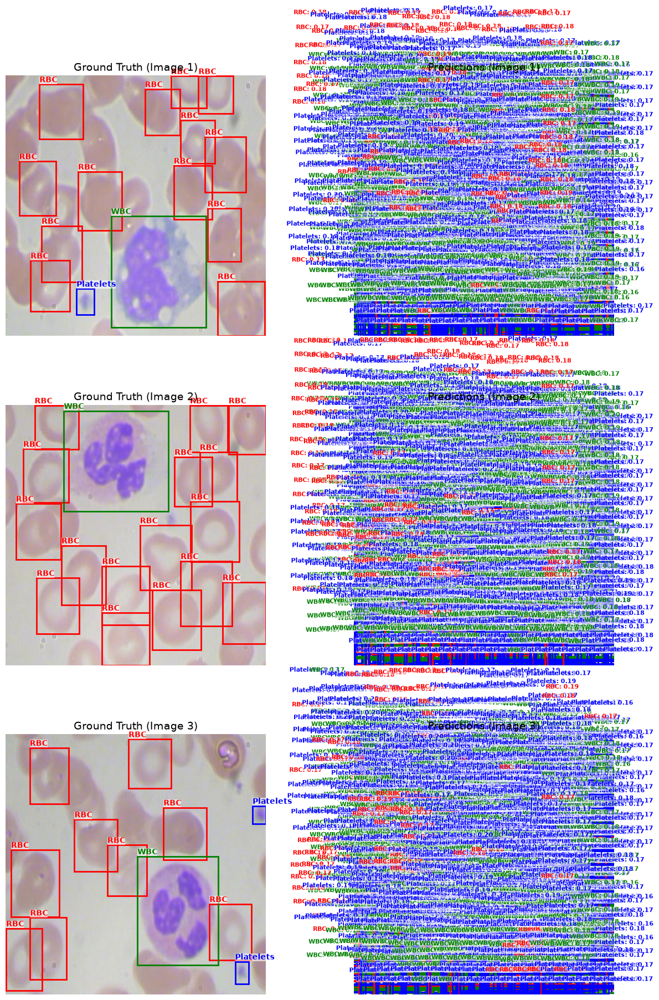

In [ ]:
# CELL 5.6: Pre-Training Visualization (Zero-Shot)
print("\n--- Visualizing Predictions BEFORE Training ---")
print("Notice how the boxes are random noise because the DetectionHead is randomlisinstancey initialized.")

# Using a low threshold (0.1) just so we can see the random garbage it tries to predict
plot_comparisons(model, val_loader, device, anchors, num_images=3, conf_thresh=0.1)

### Transfer learning

In [ ]:
# Freeze Stage A and Stage B
for param in model.stage_a.parameters():
    param.requires_grad = False
for param in model.stage_b.parameters():
    param.requires_grad = False

# We only train the detection head
optimizer = optim.Adam(model.head.parameters(), lr=1e-4, weight_decay=1e-4)

EPOCHS = 10
train_losses = []

print("\n--- Starting Transfer Learning ---")
for epoch in range(EPOCHS):
    model.train()
    epoch_loss = 0
    
    for batch_idx, (images, targets) in enumerate(train_loader):
        images, targets = images.to(device), targets.to(device)
        
        optimizer.zero_grad()
        predictions = model(images)
        
        loss = criterion(predictions, targets)
        loss.backward()
        optimizer.step()
        
        epoch_loss += loss.item()
        
    avg_train_loss = epoch_loss / len(train_loader)
    train_losses.append(avg_train_loss)
    
    print(f"Epoch [{epoch+1}/{EPOCHS}] | Train Loss: {avg_train_loss:.4f}")


--- Starting Transfer Learning ---


/tmp/ipykernel_26931/63270125.py:68: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.log(torch.tensor(w / self.anchors[best_anchor][0] + 1e-16)), # w transform
/tmp/ipykernel_26931/63270125.py:69: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.log(torch.tensor(h / self.anchors[best_anchor][1] + 1e-16))  # h transform


Epoch [1/10] | Train Loss: 420.2396
Epoch [2/10] | Train Loss: 150.4737
Epoch [3/10] | Train Loss: 91.4475
Epoch [4/10] | Train Loss: 74.3883
Epoch [5/10] | Train Loss: 50.1080
Epoch [6/10] | Train Loss: 37.9884
Epoch [7/10] | Train Loss: 33.2568
Epoch [8/10] | Train Loss: 31.5849
Epoch [9/10] | Train Loss: 31.4797
Epoch [10/10] | Train Loss: 27.1450



--- Post-Training Evaluation ---


/tmp/ipykernel_26931/63270125.py:68: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.log(torch.tensor(w / self.anchors[best_anchor][0] + 1e-16)), # w transform
/tmp/ipykernel_26931/63270125.py:69: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.log(torch.tensor(h / self.anchors[best_anchor][1] + 1e-16))  # h transform


Validation Loss: 51.9546


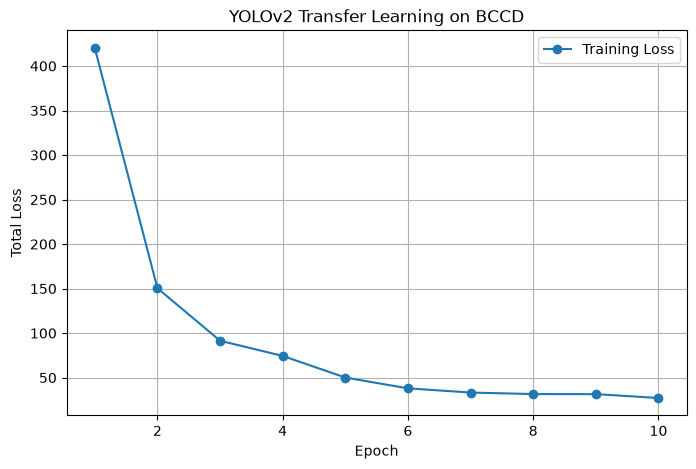

In [ ]:
from matplotlib import pyplot as plt


print("\n--- Post-Training Evaluation ---")
evaluate_model(model, val_loader, criterion, device)

# Plot the training loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, EPOCHS + 1), train_losses, marker='o', label="Training Loss")
plt.title("YOLOv2 Transfer Learning on BCCD")
plt.xlabel("Epoch")
plt.ylabel("Total Loss")
plt.legend()
plt.grid(True)
plt.show()

### Visualising some images from validation set on transfer learnt model


--- Visualizing Predictions AFTER Transfer Learning ---
Left: Labeled Ground Truth | Right: Model Predictions


/tmp/ipykernel_26931/63270125.py:68: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.log(torch.tensor(w / self.anchors[best_anchor][0] + 1e-16)), # w transform
/tmp/ipykernel_26931/63270125.py:69: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.log(torch.tensor(h / self.anchors[best_anchor][1] + 1e-16))  # h transform


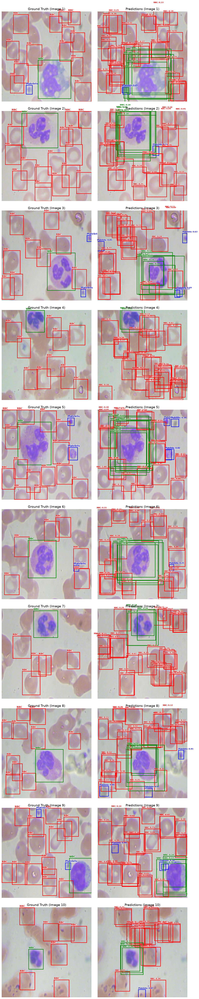

In [16]:
print("\n--- Visualizing Predictions AFTER Transfer Learning ---")
print("Left: Labeled Ground Truth | Right: Model Predictions")

# We use the standard 0.5 confidence threshold now that the model is trained
plot_comparisons(model, val_loader, device, anchors, num_images=10, conf_thresh=0.1)